In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

df = pd.read_csv("/content/ted_talks_en.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(4005, 19)


In [21]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 4005
Total columns: 19


In [22]:
print(df.dtypes)

talk_id             int64
title              object
speaker_1          object
all_speakers       object
occupations        object
about_speakers     object
views               int64
recorded_date      object
published_date     object
event              object
native_lang        object
available_lang     object
comments          float64
duration            int64
topics             object
related_talks      object
url                object
description        object
transcript         object
dtype: object


In [23]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
talk_id,4005.0,NaN,NaN,NaN,12432.538327,17447.576262,1.0,1252.0,2333.0,23777.0,62794.0
title,4005,4005,The most important anus in the ocean,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speaker_1,4005,3274,Alex Gendler,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
all_speakers,4001,3306,{0: 'Alex Gendler'},34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupations,3483,2049,{0: ['writer']},53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
about_speakers,3502,2977,{0: 'Alex Rosenthal takes everyday experiences...,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
views,4005.0,NaN,NaN,NaN,2148005.573783,3451225.523659,0.0,882069.0,1375508.0,2133110.0,65051954.0
recorded_date,4004,1334,2017-04-24,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_date,4005,2962,2017-09-07,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event,4005,459,TED-Ed,556,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
print("Unique talks:", df["talk_id"].nunique())

print(
    "Repeated talk IDs:",
    df["talk_id"].duplicated().sum()
)

Unique talks: 4005
Repeated talk IDs: 0


In [25]:
missing_values = df.isnull().sum()

print(missing_values)

talk_id             0
title               0
speaker_1           0
all_speakers        4
occupations       522
about_speakers    503
views               0
recorded_date       1
published_date      0
event               0
native_lang         0
available_lang      0
comments          655
duration            0
topics              0
related_talks       0
url                 0
description         0
transcript          0
dtype: int64


In [26]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

missing_report

,Missing Count,Missing Percentage
talk_id,0,0.00
title,0,0.00
speaker_1,0,0.00
all_speakers,4,0.10
occupations,522,13.03
about_speakers,503,12.56
views,0,0.00
recorded_date,1,0.02
published_date,0,0.00
event,0,0.00


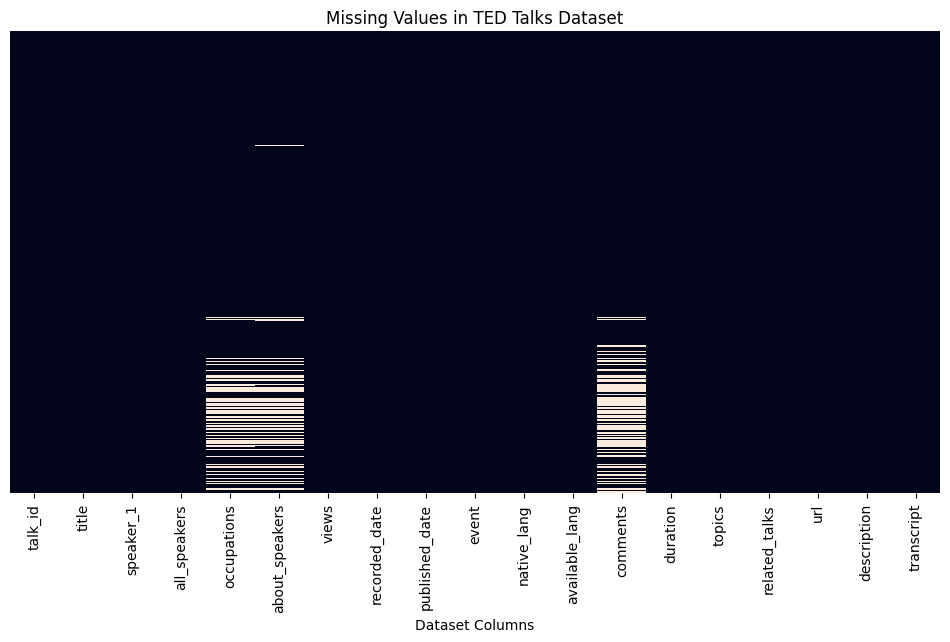

In [27]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in TED Talks Dataset")
plt.xlabel("Dataset Columns")
plt.show()

In [28]:
important_columns = [
    "title",
    "description",
    "topics",
    "transcript",
    "url"
]

for column in important_columns:

    if column in df.columns:

        empty_count = (
            df[column]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        )

        print(column, ":", empty_count)

title : 0
description : 0
topics : 0
transcript : 0
url : 0


In [29]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [30]:
print("Duplicate talk IDs:", df["talk_id"].duplicated().sum())

Duplicate talk IDs: 0


In [31]:
print("Duplicate URLs:", df["url"].duplicated().sum())

Duplicate URLs: 0


In [32]:
if "description" in df.columns:

    df["description_length"] = (
        df["description"]
        .fillna("")
        .astype(str)
        .str.len()
    )

if "transcript" in df.columns:

    df["transcript_length"] = (
        df["transcript"]
        .fillna("")
        .astype(str)
        .str.len()
    )

In [33]:
if "description" in df.columns:

    df["description_word_count"] = (
        df["description"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

if "transcript" in df.columns:

    df["transcript_word_count"] = (
        df["transcript"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

In [34]:
if "description_word_count" in df.columns:

    print("Description statistics:")

    print(df["description_word_count"].describe())

Description statistics:
count    4005.000000
mean       58.195506
std        19.430348
min         9.000000
25%        43.000000
50%        57.000000
75%        72.000000
max       143.000000
Name: description_word_count, dtype: float64


In [35]:
if "transcript_word_count" in df.columns:

    print("Transcript statistics:")

    print(df["transcript_word_count"].describe())

Transcript statistics:
count     4005.000000
mean      1796.845693
std       1004.008431
min          2.000000
25%        928.000000
50%       1753.000000
75%       2445.000000
max      11121.000000
Name: transcript_word_count, dtype: float64


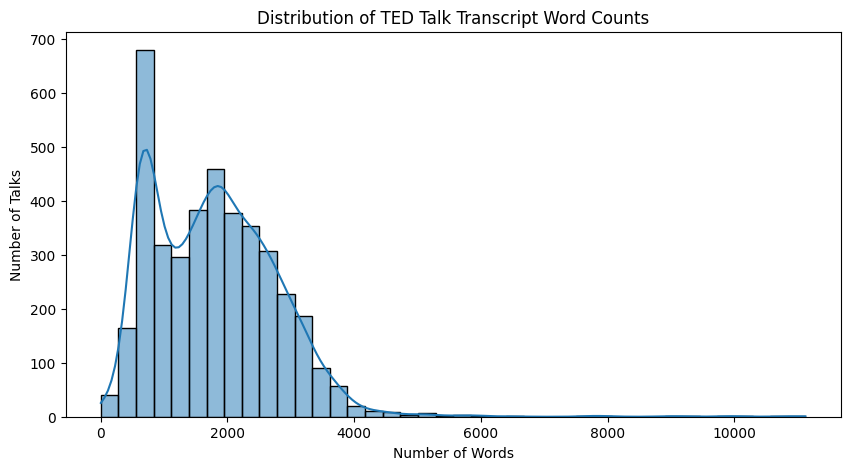

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["transcript_word_count"],
    bins=40,
    kde=True
)

plt.title("Distribution of TED Talk Transcript Word Counts")

plt.xlabel("Number of Words")

plt.ylabel("Number of Talks")

plt.show()

In [37]:
short_transcripts = df[
    df["transcript_word_count"] < 50
]

print("Talks with fewer than 50 transcript words:")

print(len(short_transcripts))

short_transcripts[
    ["title", "transcript_word_count"]
].head(10)

Talks with fewer than 50 transcript words:
10


,title,transcript_word_count
145,My magic moves,3
303,Playing invisible turntables,20
573,An all-star set,25
904,"On violin and cello, ""Passacaglia""",4
1198,Dancing with light,8
1393,"Dance, tiny robots!",4
1825,"A dance in a hurricane of paper, wind and light",2
1948,An 11-year-old prodigy performs old-school jazz,4
2029,A musical escape into a world of light and color,19
2330,An electrifying acoustic guitar performance,7


In [38]:
def extract_tags(value):

    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:

        parsed = ast.literal_eval(str(value))

        if isinstance(parsed, list):
            return parsed

    except (ValueError, SyntaxError):
        pass

    return []

In [39]:
df["processed_tags"] = df["topics"].apply(extract_tags)

print(df["processed_tags"].head())

0    [alternative energy, cars, climate change, cul...
1    [Africa, Asia, Google, demo, economics, global...
2    [computers, entertainment, interface design, m...
3    [MacArthur grant, activism, business, cities, ...
4    [children, creativity, culture, dance, educati...
Name: processed_tags, dtype: object


In [40]:
from collections import Counter

all_tags = []

for tags in df["processed_tags"]:

    all_tags.extend([
        str(tag).strip().lower()
        for tag in tags
        if str(tag).strip()
    ])

tag_counts = Counter(all_tags)

tag_frequency = pd.DataFrame(
    tag_counts.most_common(15),
    columns=["Tag", "Frequency"]
)

tag_frequency

,Tag,Frequency
0,science,993
1,technology,979
2,culture,680
3,tedx,581
4,global issues,574
5,ted-ed,563
6,society,557
7,design,518
8,social change,512
9,animation,487


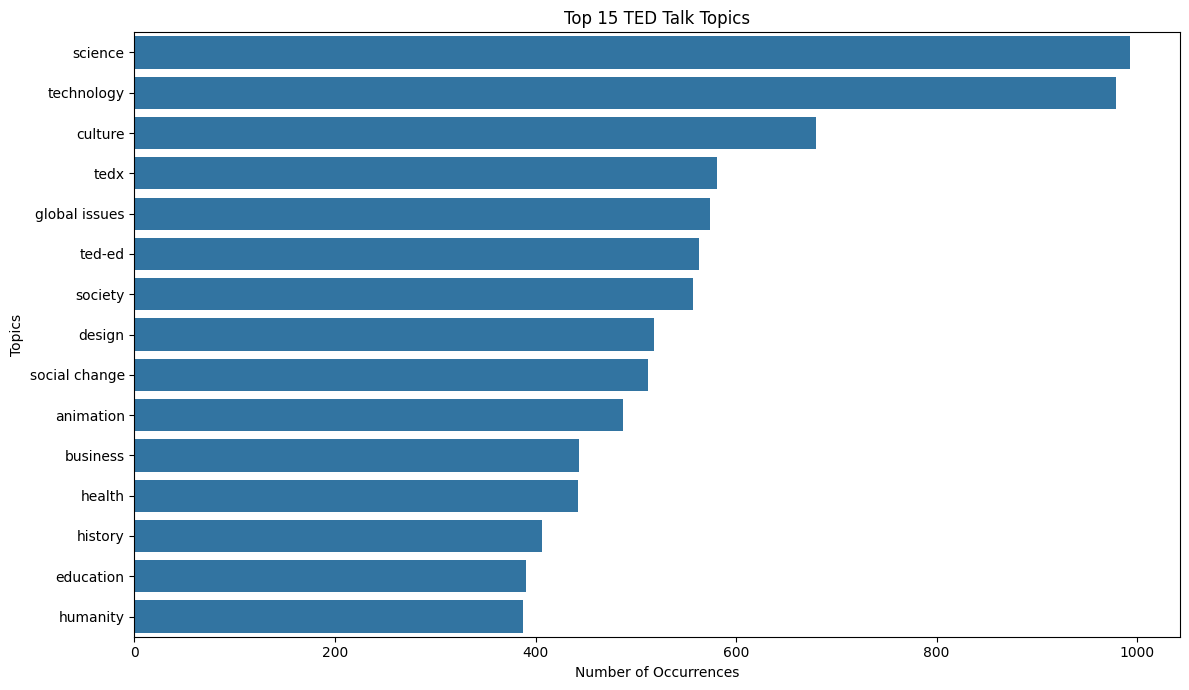

In [41]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=tag_frequency,
    x="Frequency",
    y="Tag"
)

plt.title("Top 15 TED Talk Topics")

plt.xlabel("Number of Occurrences")

plt.ylabel("Topics")

plt.tight_layout()

plt.show()

In [42]:
if "views" in df.columns:

    print("Views statistics:")

    print(df["views"].describe())

Views statistics:
count    4.005000e+03
mean     2.148006e+06
std      3.451226e+06
min      0.000000e+00
25%      8.820690e+05
50%      1.375508e+06
75%      2.133110e+06
max      6.505195e+07
Name: views, dtype: float64


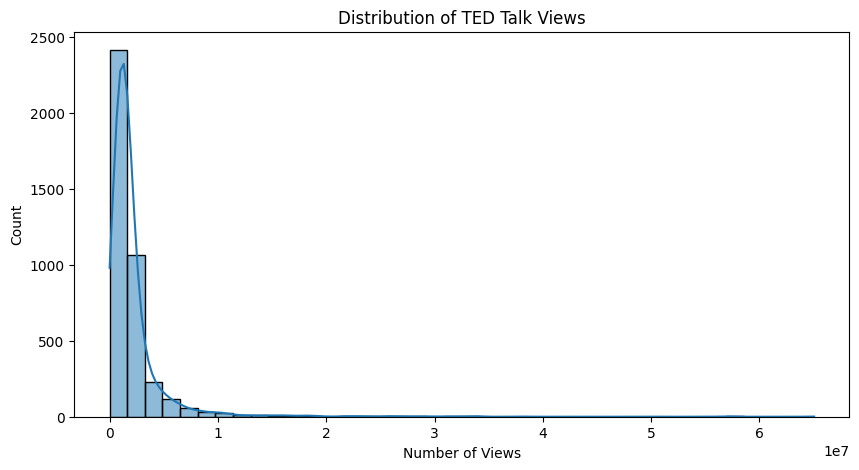

In [43]:
if "views" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["views"],
        bins=40,
        kde=True
    )

    plt.title("Distribution of TED Talk Views")

    plt.xlabel("Number of Views")

    plt.show()

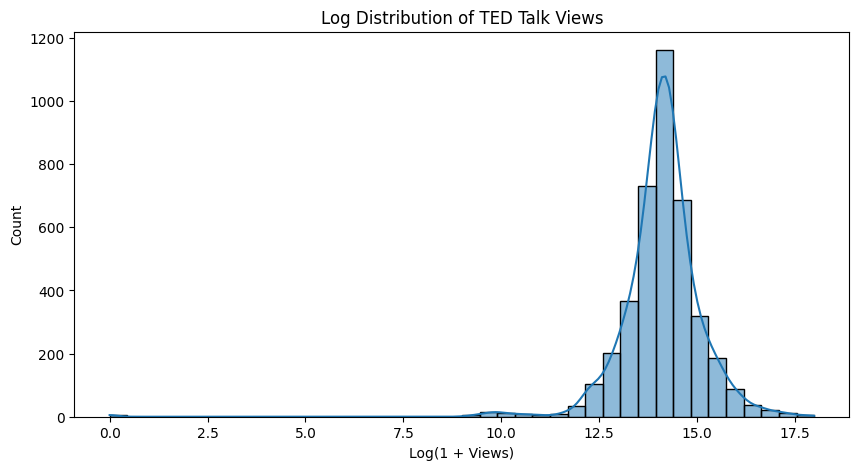

In [44]:
if "views" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        np.log1p(df["views"]),
        bins=40,
        kde=True
    )

    plt.title("Log Distribution of TED Talk Views")

    plt.xlabel("Log(1 + Views)")

    plt.show()

In [45]:
if "duration" in df.columns:

    print("Duration statistics:")

    print(df["duration"].describe())

Duration statistics:
count    4005.000000
mean      724.011236
std       361.775462
min        60.000000
25%       393.000000
50%       738.000000
75%       974.000000
max      3922.000000
Name: duration, dtype: float64


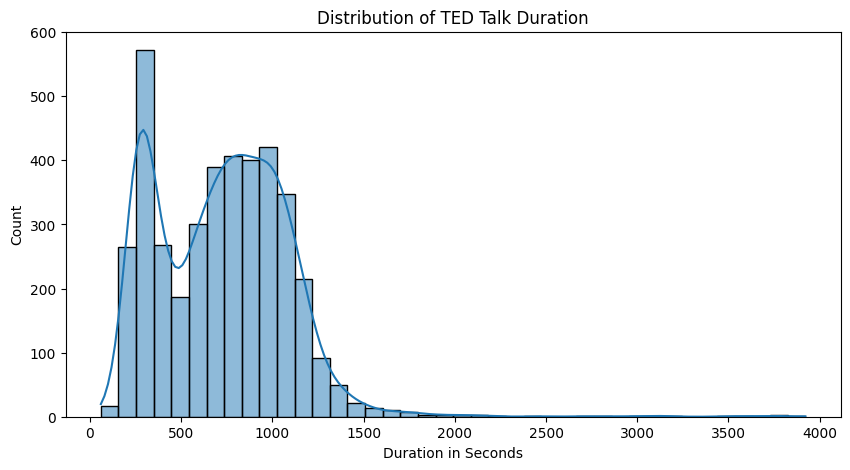

In [46]:
if "duration" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["duration"],
        bins=40,
        kde=True
    )

    plt.title("Distribution of TED Talk Duration")

    plt.xlabel("Duration in Seconds")

    plt.show()

In [50]:
print("EDA FINDINGS")

print("1. Total number of talks:", len(df))

print("2. Number of columns:", len(df.columns))

print(
    "3. Unique TED Talks:",
    df["talk_id"].nunique()
)

# Exclude columns with lists or dicts to avoid unhashable type errors during duplication check
hashable_cols = [col for col in df.columns if not isinstance(df[col].iloc[0], (list, dict))]
print(
    "4. Duplicate records (excluding list/dict columns):",
    df[hashable_cols].duplicated().sum()
)

print(
    "5. Missing transcript values:",
    df["transcript"].isnull().sum()
)

print(
    "6. Missing description values:",
    df["description"].isnull().sum()
)

print(
    "7. Missing title values:",
    df["title"].isnull().sum()
)

print(
    "8. Total unique tags:",
    len(tag_counts)
)

print(
    "9. Most frequent tags:",
    tag_frequency.head(5)["Tag"].tolist()
)

print(
    "10. Average transcript word count:",
    round(df["transcript_word_count"].mean(), 2)
)

EDA FINDINGS
1. Total number of talks: 4005
2. Number of columns: 24
3. Unique TED Talks: 4005
4. Duplicate records (excluding list/dict columns): 0
5. Missing transcript values: 0
6. Missing description values: 0
7. Missing title values: 0
8. Total unique tags: 457
9. Most frequent tags: ['science', 'technology', 'culture', 'tedx', 'global issues']
10. Average transcript word count: 1796.85
